In [15]:
!uv pip install opencv-python numpy matplotlib

Using Python 3.12.7 environment at: /Users/hydroxide/Desktop/Projects/badminton-analysis/.venv
Audited 3 packages in 26ms


In [16]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

## Playing Around with CV2

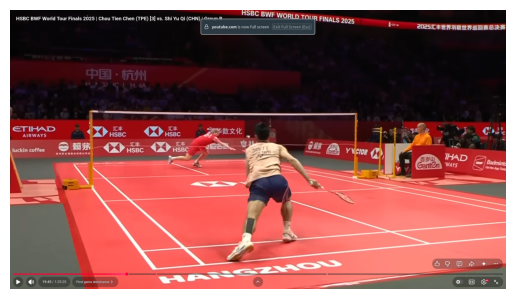

In [17]:
frame = cv2.imread('../test_data/shot3.png')
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

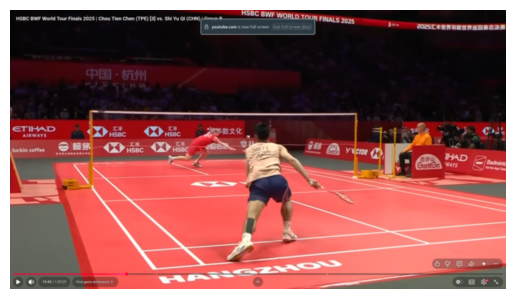

In [18]:
gaussian = cv2.GaussianBlur(frame, (11, 11), 0.0)
plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

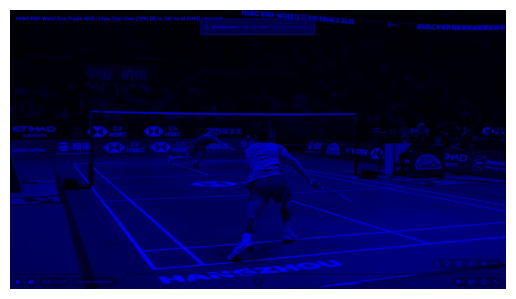

In [19]:
# b,g,r = cv2.split(frame)

r = frame.copy()
r[:,:,0:2] = 0

b = frame.copy()
b[:,:,1:3] = 0

g = frame.copy()
g[:,:,0:3:2] = 0

assert r[0,0,0] == 0
assert r[0,0,1] == 0

assert g[0,0,0] == 0
assert g[0,0,2] == 0

assert b[0,0,1] == 0
assert b[0,0,2] == 0

plt.imshow(cv2.cvtColor(b, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

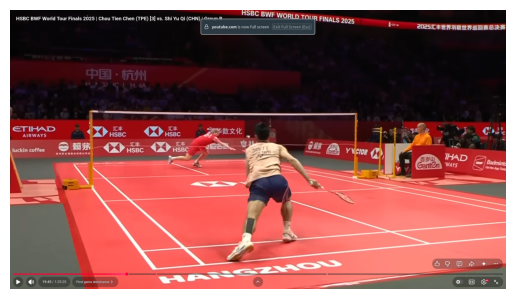

In [20]:
img_reconstructed = r + g + b
plt.imshow(cv2.cvtColor(img_reconstructed, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

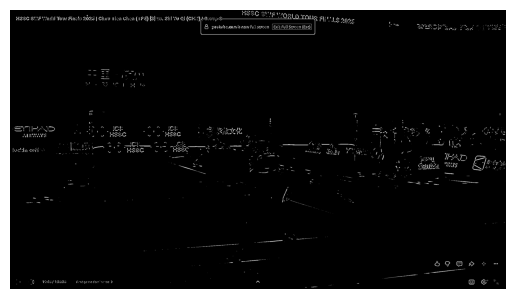

In [21]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

s = hsv[:, :, 1].astype(np.float32)
v = hsv[:, :, 2].astype(np.float32)

t = 4
v_diff = 20
s_diff = 15

def local_contrast(channel, t, delta, brighter=True):
    center = channel[t:-t, t:-t]

    left   = channel[t:-t, :-2*t]
    right  = channel[t:-t, 2*t:]
    top    = channel[:-2*t, t:-t]
    bottom = channel[2*t:, t:-t]

    if brighter:
        horizontal = ((center - left > delta) &
                      (center - right > delta))
        vertical = ((center - top > delta) &
                    (center - bottom > delta))
    else:
        horizontal = ((left - center > delta) &
                      (right - center > delta))
        vertical = ((top - center > delta) &
                    (bottom - center > delta))

    result = np.zeros(channel.shape, dtype=bool)
    result[t:-t, t:-t] = horizontal | vertical

    return result

# Brighter than neighbouring pixels
brightness_mask = local_contrast(v, t, v_diff, brighter=True)

# Less saturated than neighbouring pixels
saturation_mask = local_contrast(s, t, s_diff, brighter=False)

# Combine both conditions
mask = (brightness_mask & saturation_mask).astype(np.uint8) * 255

plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()

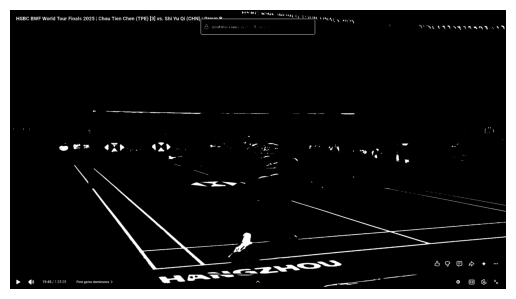

In [22]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

lower = [0, 0, 150]
upper = [75, 50, 255]

mask = cv2.inRange(
    hsv,
    np.array(lower),
    np.array(upper)
)

plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()

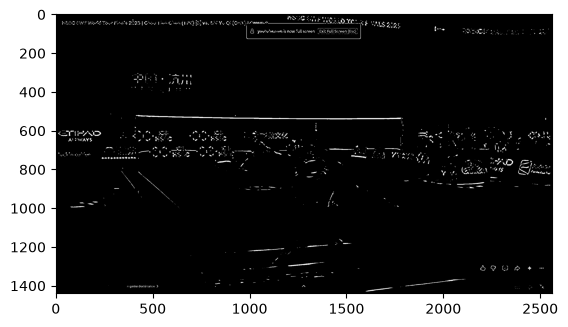

In [23]:
t = 8
v_diff = 30
s_diff = 30

def local_contrast(channel, t, delta, brighter=True):
    center = channel[t:-t, t:-t]

    left   = channel[t:-t, :-2*t]
    right  = channel[t:-t, 2*t:]
    top    = channel[:-2*t, t:-t]
    bottom = channel[2*t:, t:-t]

    if brighter:
        horizontal = ((center - left > delta) &
                      (center - right > delta))
        vertical = ((center - top > delta) &
                    (center - bottom > delta))
    else:
        horizontal = ((left - center > delta) &
                      (right - center > delta))
        vertical = ((top - center > delta) &
                    (bottom - center > delta))

    result = np.zeros(channel.shape, dtype=bool)
    result[t:-t, t:-t] = horizontal | vertical

    return result

# Brighter than neighbouring pixels
brightness_mask = local_contrast(v, t, v_diff, brighter=True)

# Less saturated than neighbouring pixels
saturation_mask = local_contrast(s, t, s_diff, brighter=False)

# Combine both conditions
mask = (brightness_mask & saturation_mask).astype(np.uint8) * 255

plt.imshow(mask, cmap="gray")
plt.show()

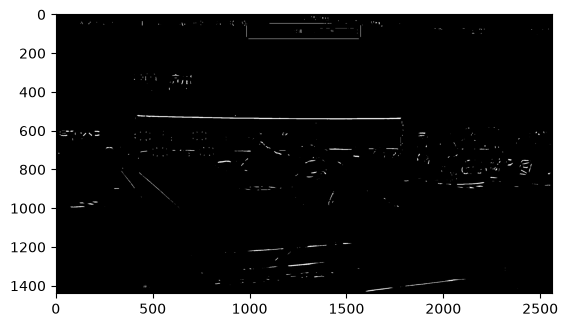

In [24]:
# Use original brightness channel
image = v.astype(np.float32)

# 1. Smooth image to reduce noise
image = cv2.GaussianBlur(image, (5, 5), 0)

# 2. Compute image gradients
dx = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=3)
dy = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=3)

# 3. Compute structure tensor components
window = (21, 21)

Jxx = cv2.boxFilter(dx * dx, -1, window)
Jxy = cv2.boxFilter(dx * dy, -1, window)
Jyy = cv2.boxFilter(dy * dy, -1, window)

# 4. Compute the two eigenvalues
discriminant = np.sqrt(
    (Jxx - Jyy)**2 + 4 * Jxy**2
)

lambda1 = (Jxx + Jyy + discriminant) / 2
lambda2 = (Jxx + Jyy - discriminant) / 2

# 5. Select linear structures
linear = lambda1 > 4 * np.maximum(lambda2, 0)

# 6. Keep only existing candidate pixels
final_mask = ((mask > 0) & linear).astype(np.uint8) * 255

plt.imshow(final_mask, cmap="gray")
plt.show()

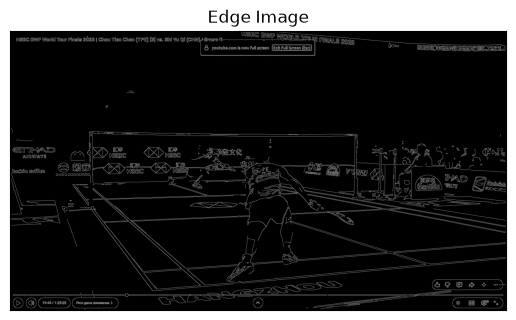

In [39]:
edges = cv2.Canny(frame, 100, 150)

plt.imshow(edges,cmap = 'gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])

plt.show()